## 01. Mục tiêu

Dự đoán GPA cuối kỳ và khảo sát mối liên hệ có điều kiện giữa thời gian AI, mục đích sử dụng và kỹ năng prompt. Đây là dữ liệu synthetic; không suy ra tác động nhân quả.

## 02. Thiết lập

Chạy từ thư mục dự án; mã tự tìm thư mục gốc. Các kết quả sẽ được lưu dưới `outputs/interaction`. Không tải dữ liệu tự động.

In [1]:
from pathlib import Path
import os, sys
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('OMP_NUM_THREADS', '1')
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'pyproject.toml').exists() and (p/'src/lab01_ml').exists()), None)
if ROOT is None: raise FileNotFoundError('Không tìm thấy project root; mở notebook trong dự án.')
sys.path.insert(0, str(ROOT/'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib, json
from IPython.display import display
from lab01_ml.features.engineering import InteractionFeatures, INPUTS, H, P, S
from lab01_ml.models.training import load_frozen, development, metrics, TARGET
from lab01_ml.models.inference import predict_student
OUT = ROOT/'outputs/interaction'; FIG = OUT/'figures'; TABLES = OUT/'tables'; MODELS = OUT/'models'
for p in (FIG, TABLES, MODELS): p.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
def show(fig, name, observation):
    fig.tight_layout(); fig.savefig(FIG/(name+'.png'), dpi=160, bbox_inches='tight'); display(fig); plt.close(fig)
    print('Nhận xét từ dữ liệu:', observation)


## 03. Đầu vào và mục tiêu

Có 12 biến đầu vào; mục tiêu duy nhất là `Post_Semester_GPA`. Các biến này chỉ phù hợp dự báo khi có sẵn ở thời điểm dự đoán.

In [2]:
display(pd.DataFrame({'Đầu vào':INPUTS})); print('Target:', TARGET)

,Đầu vào
0,Pre_Semester_GPA
1,Traditional_Study_Hours
2,Year_of_Study
3,Major_Category
4,Weekly_GenAI_Hours
5,Primary_Use_Case
6,Prompt_Engineering_Skill
7,Tool_Diversity
8,Paid_Subscription
9,Institutional_Policy


Target: Post_Semester_GPA


## 04. Tránh rò rỉ

`Student_ID`, `GPA_Change`, `Skill_Retention_Score`, `Burnout_Risk_Level` và target không thuộc X. GPA Change chỉ được tính để minh họa; mọi thông số tiền xử lý học từ train hoặc training fold.

## 05. Thời điểm đo

Dependency và Anxiety có thời điểm thu thập chưa xác minh. Mô hình đầy đủ mang tính conditional/retrospective; trước kỳ thi không được dùng Anxiety nếu chưa có. No-D vẫn cần xác minh availability các biến còn lại.

## 06. Split cố định

Dùng ba tập hiện có; kiểm hash, ID và assignment. Phân phối: train cho học và CV, validation để đối chiếu, test giữ kín đến sau khóa model.

In [3]:
frames, provenance = load_frozen(ROOT)
train, val = frames['train'], frames['validation']
display(pd.DataFrame([provenance['counts']]))
(OUT/'train_split_provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf8')
print('Phê duyệt split chung:', provenance['group_approval'])

,train,validation,test
0,35000,7500,7500


Phê duyệt split chung: unconfirmed


## 07. Sơ đồ dữ liệu

Kiểm tra tên cột, số dòng và giá trị thiếu trên train; các thống kê EDA sau đây không dùng test.

In [4]:
display(train.dtypes.rename('dtype').to_frame().assign(missing=train.isna().sum()))

,dtype,missing
Student_ID,object,0
Major_Category,object,0
Year_of_Study,object,0
Pre_Semester_GPA,float64,0
Weekly_GenAI_Hours,float64,0
Primary_Use_Case,object,0
Prompt_Engineering_Skill,object,0
Tool_Diversity,int64,0
Paid_Subscription,bool,0
Traditional_Study_Hours,float64,0


## 08. Phân phối GPA

Biểu đồ biểu diễn nhãn train và cho biết miền GPA quan sát.

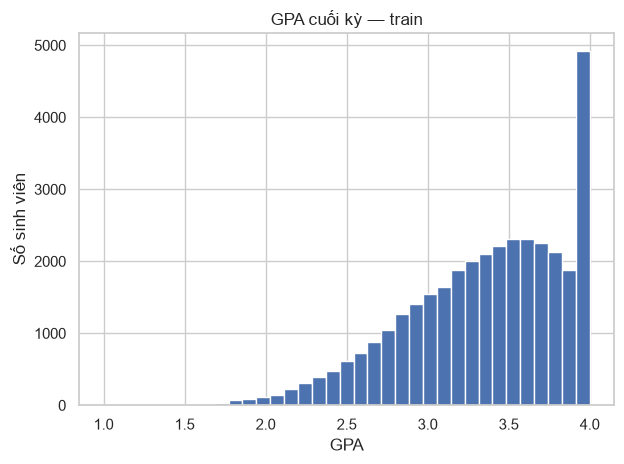

Nhận xét từ dữ liệu: Trung vị GPA train = 3.421; n = 35000.


In [5]:
fig, ax=plt.subplots(); ax.hist(train[TARGET],bins=35); ax.set(title='GPA cuối kỳ — train',xlabel='GPA',ylabel='Số sinh viên')
show(fig,'01_gpa_distribution',f"Trung vị GPA train = {train[TARGET].median():.3f}; n = {len(train)}.")

## 09. Phân phối giờ AI

Dùng histogram để nhận diện miền và mức tập trung của số giờ.

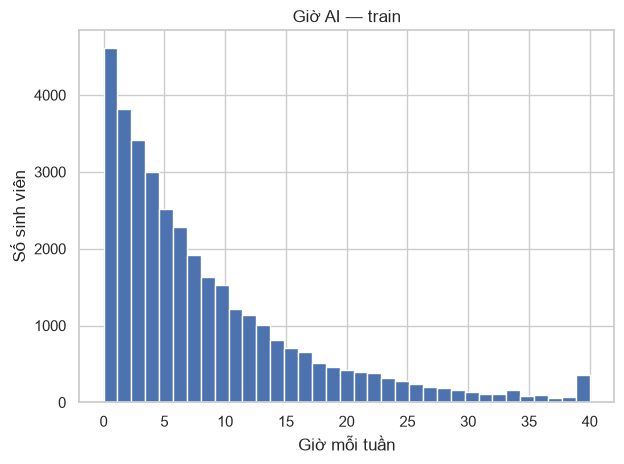

Nhận xét từ dữ liệu: Trung vị = 5.78 giờ; Q1–Q3 = 2.39–11.73.


In [6]:
fig,ax=plt.subplots(); ax.hist(train[H],bins=35); ax.set(title='Giờ AI — train',xlabel='Giờ mỗi tuần',ylabel='Số sinh viên')
show(fig,'02_ai_hours',f"Trung vị = {train[H].median():.2f} giờ; Q1–Q3 = {train[H].quantile(.25):.2f}–{train[H].quantile(.75):.2f}.")

## 10. GPA thay đổi và giờ AI

GPA Change là `Post − Pre`, chỉ dùng mô tả trên train; không bao giờ là đầu vào dự đoán Post GPA.

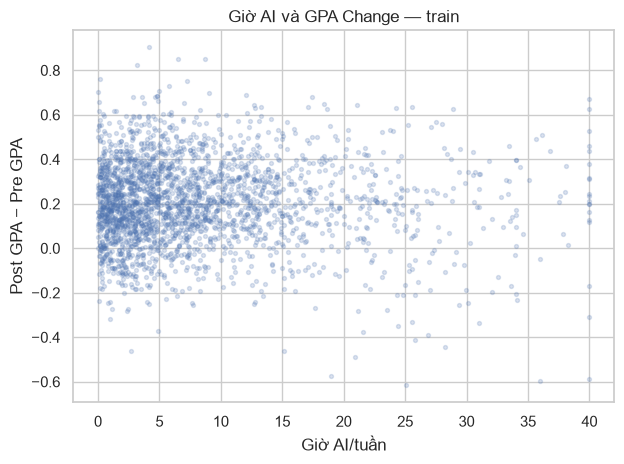

Nhận xét từ dữ liệu: GPA Change trung bình train = 0.203; đây chỉ là mô tả.


In [7]:
change=train[TARGET]-train[P]
fig,ax=plt.subplots(); ix=train.sample(min(2500,len(train)),random_state=42).index; ax.scatter(train.loc[ix,H],change.loc[ix],alpha=.2,s=8); ax.set(title='Giờ AI và GPA Change — train',xlabel='Giờ AI/tuần',ylabel='Post GPA − Pre GPA')
show(fig,'03_ai_gpa_change',f"GPA Change trung bình train = {change.mean():.3f}; đây chỉ là mô tả.")

## 11. Nhóm Use Case × Prompt Skill

Các ô là GPA quan sát trung bình, không phải tác động của nhóm.

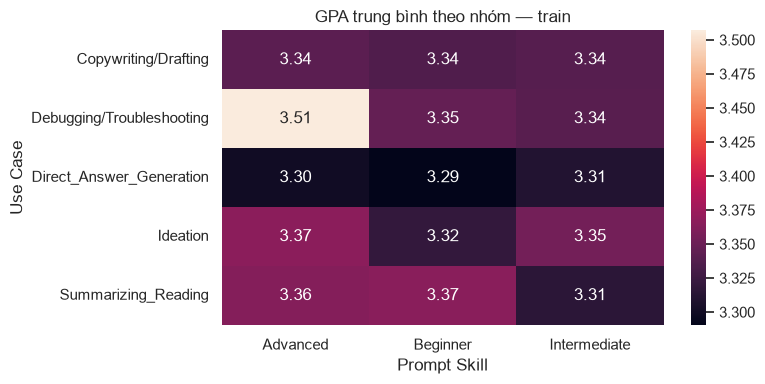

Nhận xét từ dữ liệu: Khoảng trung bình các ô quan sát: 3.290–3.507.


In [8]:
group=train.pivot_table(index='Primary_Use_Case',columns='Prompt_Engineering_Skill',values=TARGET,aggfunc='mean')
fig,ax=plt.subplots(figsize=(8,4)); sns.heatmap(group,annot=True,fmt='.2f',ax=ax); ax.set(title='GPA trung bình theo nhóm — train',xlabel='Prompt Skill',ylabel='Use Case')
show(fig,'04_group_heatmap',f"Khoảng trung bình các ô quan sát: {group.min().min():.3f}–{group.max().max():.3f}.")

## 12. Hồi quy OLS

OLS tìm hệ số tối thiểu hóa tổng bình phương sai số: $$\min_\beta \sum_i(y_i-\hat y_i)^2,\qquad \hat y_i=\beta_0+\beta^T x_i.$$ Hệ số không mặc định có ý nghĩa thống kê.

## 13. Centring

Đặt $H_c=H-\bar H_{train}$, $P_c=P-\bar P_{train}$ và $S_c=S-\bar S_{train}$. Trong CV, các trung bình được học riêng từ phần training của fold.

## 14. Reference coding

Mỗi biến phân loại bỏ một mức làm reference. $U_i$ là dummy Use Case; $K_j$ là dummy Prompt Skill. Category lạ được cảnh báo và mã hóa toàn 0; không thể phân biệt với reference.

## 15. Interaction và độ dốc

I3: $$\hat y=\beta_0+\beta^T X_{main}+\sum_j\gamma_j H_cK_j+\sum_i\delta_i H_cU_i+\sum_{ij}\eta_{ij}U_iK_j.$$ Với nhóm $(u,k)$, $\partial\hat y/\partial H=\beta_H+\gamma_k+\delta_u$; reference có phần cộng bằng 0. I4 thêm $\theta H_cP_c+\phi H_cS_c$.

## 16. Ví dụ tính tay

Giả sử $\beta_H=0.02$, $\gamma_k=-0.005$, $\delta_u=0.003$. Độ dốc của nhóm là $0.018$ GPA/giờ theo mô hình, không phải tác động nhân quả.

In [9]:
print('Độ dốc minh họa:', 0.02 - 0.005 + 0.003, 'GPA/giờ')

Độ dốc minh họa: 0.018 GPA/giờ


## 17. Năm cấu hình lồng nhau

I0 chỉ main effects; I1 thêm Hc×K; I2 thêm Hc×U; I3 thêm U×K; I4 tùy chọn thêm Hc×Pc và Hc×Sc. Counts không bao gồm intercept.

In [10]:
for i, expected in enumerate([39,41,45,53,55]):
    ft=InteractionFeatures(model=i).fit(train[INPUTS]); actual=len(ft.get_feature_names_out())
    print(f'I{i}: {actual} predictor terms (đủ levels: {expected})')
    if all(len(x)==n for x,n in zip(ft.encoder_.categories_,[5,5,5,3,3,10,10])): assert actual == expected
feature_table=pd.DataFrame({'feature':InteractionFeatures(model=3).fit(train[INPUTS]).get_feature_names_out()})
display(feature_table)

I0: 39 predictor terms (đủ levels: 39)
I1: 41 predictor terms (đủ levels: 41)


I2: 45 predictor terms (đủ levels: 45)


I3: 53 predictor terms (đủ levels: 53)


I4: 55 predictor terms (đủ levels: 55)


,feature
0,Hc
1,Pc
2,Sc
3,Tool_Diversity
4,Paid_Subscription
5,Year_of_Study=Graduate
6,Year_of_Study=Junior
7,Year_of_Study=Senior
8,Year_of_Study=Sophomore
9,Major_Category=Business


## 18. Một hàng sau biến đổi

So sánh giá trị Hc của hàng đầu với phép trừ trung bình train.

In [11]:
ft=InteractionFeatures(model=3).fit(train[INPUTS]); transformed=ft.transform(train[INPUTS].iloc[[0]])
print('Tính tay Hc:', float(train.iloc[0][H])-ft.means_[H], ' | Transformer:', transformed[0,0]); display(pd.DataFrame(transformed,columns=ft.get_feature_names_out()).T.head(15))

Tính tay Hc: 14.865062857142856  | Transformer: 14.865062857142856


,0
Hc,14.865063
Pc,-0.728429
Sc,-3.072107
Tool_Diversity,1.000000
Paid_Subscription,1.000000
Year_of_Study=Graduate,0.000000
Year_of_Study=Junior,0.000000
Year_of_Study=Senior,1.000000
Year_of_Study=Sophomore,0.000000
Major_Category=Business,0.000000


## 19. Cross-validation

Chia train thành 5 fold cố định với seed 42. Mỗi fold fit lại toàn bộ preprocessing; validation và test không tham gia fit. Kết quả phụ thuộc máy và không có RMSE kỳ vọng.

## 20. Huấn luyện và validation

Tính 4 metrics theo từng fold, mean ± sample SD; hai ablation I3 chỉ được đánh giá trên development.

In [12]:
folds, comparison, models, valpred, selected = development(train, val, include_i4=True)
folds.to_csv(TABLES/'cv_folds.csv',index=False); comparison.to_csv(TABLES/'comparison.csv',index=False)
display(comparison); print('Chọn theo CV trước test:', selected)

,model,cv_mae_mean,cv_mae_std,cv_mse_mean,cv_mse_std,cv_rmse_mean,cv_rmse_std,cv_r2_mean,cv_r2_std,val_mae,val_mse,val_rmse,val_r2,terms
0,I0,0.125483,0.001709,0.025629,0.000481,0.160084,0.001507,0.895350,0.001134,0.126067,0.025666,0.160207,0.896272,39.0
1,I1,0.125447,0.001703,0.025625,0.000475,0.160072,0.001489,0.895367,0.001099,0.126041,0.025675,0.160235,0.896236,41.0
2,I2,0.122100,0.001950,0.023635,0.000609,0.153726,0.001995,0.903507,0.000754,0.122334,0.023582,0.153565,0.904695,45.0
3,I3,0.119787,0.001803,0.022652,0.000588,0.150496,0.001965,0.907518,0.000972,0.119915,0.022707,0.150687,0.908234,53.0
4,I3_no_anxiety,0.119856,0.001751,0.022674,0.000585,0.150567,0.001954,0.907430,0.000971,0.120059,0.022752,0.150837,0.908051,44.0
5,I3_no_d,0.120083,0.001692,0.022746,0.000578,0.150808,0.001928,0.907133,0.000980,0.120272,0.022840,0.151130,0.907694,35.0
6,I4,0.119774,0.001795,0.022646,0.000586,0.150477,0.001960,0.907541,0.000982,0.119850,0.022683,0.150608,0.908330,55.0


Chọn theo CV trước test: I3


## 21. CV RMSE

Sai số trung bình và độ lệch chuẩn giữa các fold.

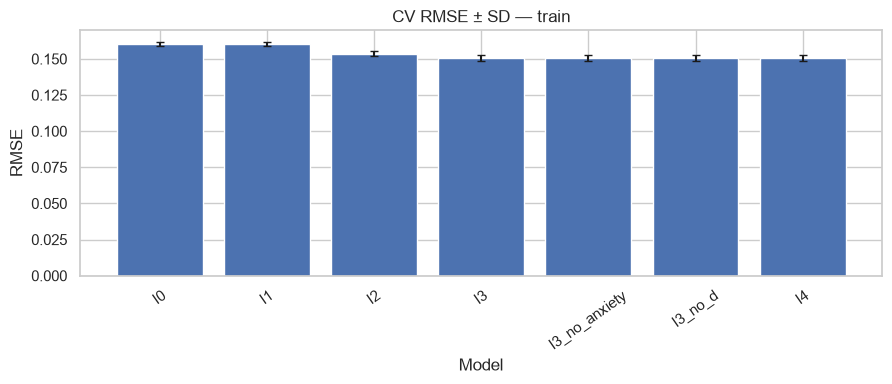

Nhận xét từ dữ liệu: RMSE CV nhỏ nhất = 0.1505; model chọn theo tie rule là I3.


In [13]:
fig,ax=plt.subplots(figsize=(9,4)); ax.bar(comparison.model,comparison.cv_rmse_mean,yerr=comparison.cv_rmse_std,capsize=3); ax.tick_params(axis='x',rotation=35); ax.set(title='CV RMSE ± SD — train',xlabel='Model',ylabel='RMSE')
show(fig,'05_cv_rmse',f"RMSE CV nhỏ nhất = {comparison.cv_rmse_mean.min():.4f}; model chọn theo tie rule là {selected}.")

## 22. Validation RMSE

Validation là kiểm tra mô tả, không được dùng thay đổi lựa chọn CV.

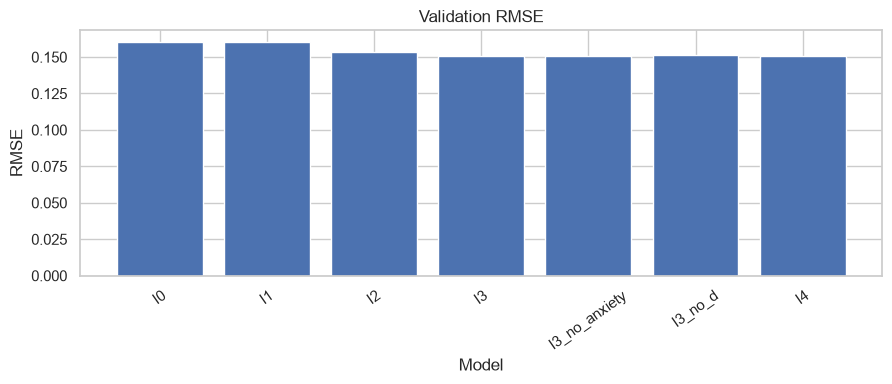

Nhận xét từ dữ liệu: Validation RMSE của I3 = 0.1507.


In [14]:
fig,ax=plt.subplots(figsize=(9,4)); ax.bar(comparison.model,comparison.val_rmse); ax.tick_params(axis='x',rotation=35); ax.set(title='Validation RMSE',xlabel='Model',ylabel='RMSE')
show(fig,'06_val_rmse',f"Validation RMSE của {selected} = {comparison.set_index('model').loc[selected,'val_rmse']:.4f}.")

## 23. Ablation lồng nhau

Bảng và hình cho biết sự khác biệt giữa các tập terms, không chứng minh nhân quả.

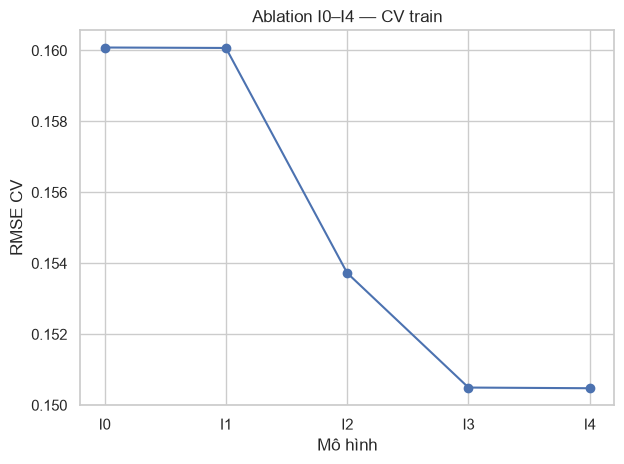

Nhận xét từ dữ liệu: Chênh lệch RMSE I3 − I0 = -0.0096.


In [15]:
main=comparison[comparison.model.isin([f'I{i}' for i in range(5)])].sort_values('model')
fig,ax=plt.subplots(); ax.plot(main.model,main.cv_rmse_mean,marker='o'); ax.set(title='Ablation I0–I4 — CV train',xlabel='Mô hình',ylabel='RMSE CV')
show(fig,'07_ablation',f"Chênh lệch RMSE I3 − I0 = {main.set_index('model').loc['I3','cv_rmse_mean']-main.set_index('model').loc['I0','cv_rmse_mean']:.4f}.")

## 24. Coefficients và baseline

Hc=0 là tại trung bình train; hệ số chính là slope của nhóm reference. Đơn vị gốc được giữ vì không chuẩn hóa.

In [16]:
i3=models['I3']; f3=i3.named_steps['features']; coefficients=pd.Series(i3.named_steps['ols'].coef_,index=f3.get_feature_names_out())
print('Mức reference:',f3.references_); display(coefficients.rename('coefficient').to_frame()); print('Intercept:',i3.named_steps['ols'].intercept_)

Mức reference: {'Year_of_Study': 'Freshman', 'Major_Category': 'Arts', 'Primary_Use_Case': 'Copywriting/Drafting', 'Prompt_Engineering_Skill': 'Advanced', 'Institutional_Policy': 'Actively_Encouraged', 'Perceived_AI_Dependency': '1', 'Anxiety_Level_During_Exams': '1'}


,coefficient
Hc,0.003137
Pc,0.962233
Sc,0.013685
Tool_Diversity,0.000034
Paid_Subscription,0.011295
Year_of_Study=Graduate,0.119292
Year_of_Study=Junior,0.092119
Year_of_Study=Senior,0.111584
Year_of_Study=Sophomore,0.043065
Major_Category=Business,0.000435


Intercept: 3.2814320682983853


## 25. Độ dốc có điều kiện

Tính slope từ dự đoán tại hai giá trị giờ AI liên tiếp, giữ các biến khác cố định; cách này bao gồm tất cả interactions.

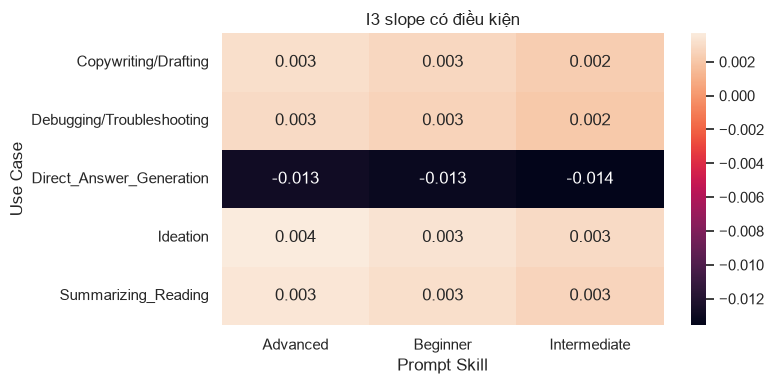

Nhận xét từ dữ liệu: Slope nhóm reference = 0.0031 GPA/giờ; không là hiệu ứng nhân quả.


In [17]:
profile=train.iloc[0][INPUTS].to_dict(); uses=list(f3.encoder_.categories_[f3.cat_columns_.index('Primary_Use_Case')]); skills=list(f3.encoder_.categories_[f3.cat_columns_.index('Prompt_Engineering_Skill')]); slopes=pd.DataFrame(index=uses,columns=skills,dtype=float)
for u in uses:
 for k in skills:
  a=profile|{'Primary_Use_Case':u,'Prompt_Engineering_Skill':k,H:f3.means_[H]}; b=a|{H:a[H]+1}
  slopes.loc[u,k]=i3.predict(pd.DataFrame([b]))[0]-i3.predict(pd.DataFrame([a]))[0]
fig,ax=plt.subplots(figsize=(8,4)); sns.heatmap(slopes,annot=True,fmt='.3f',ax=ax); ax.set(title='I3 slope có điều kiện',xlabel='Prompt Skill',ylabel='Use Case')
show(fig,'08_conditional_slopes',f"Slope nhóm reference = {slopes.iloc[0,0]:.4f} GPA/giờ; không là hiệu ứng nhân quả.")

## 26. Đường dự đoán theo nhóm

Thay giờ AI trên lưới, giữ profile còn lại cố định. Khoảng ngoài dữ liệu quan sát không nên diễn giải như dự báo đáng tin.

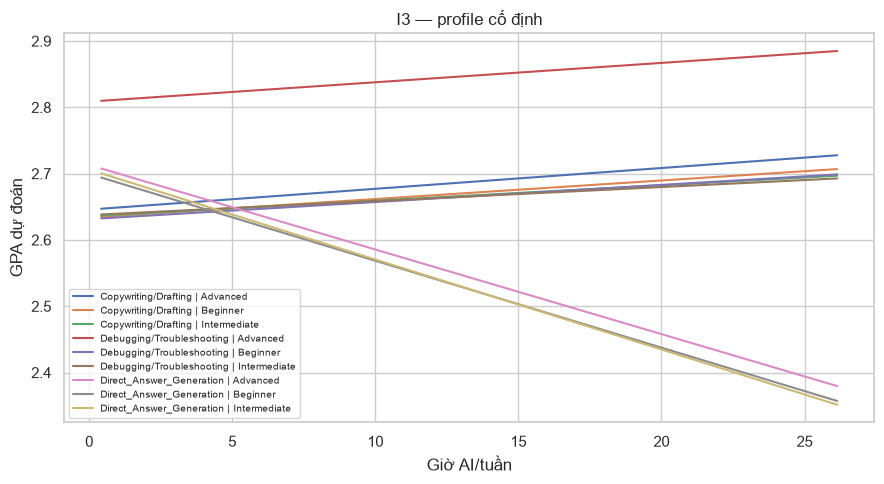

Nhận xét từ dữ liệu: Giữ các biến khác theo profile train; khoảng giờ minh họa 0.4–26.1.


In [18]:
fig,ax=plt.subplots(figsize=(9,5)); grid=np.linspace(train[H].quantile(.05),train[H].quantile(.95),40)
for u in uses[:3]:
 for k in skills:
  X=pd.DataFrame([profile|{H:h,'Primary_Use_Case':u,'Prompt_Engineering_Skill':k} for h in grid]); ax.plot(grid,i3.predict(X),label=f'{u} | {k}')
ax.set(title='I3 — profile cố định',xlabel='Giờ AI/tuần',ylabel='GPA dự đoán'); ax.legend(fontsize=7)
show(fig,'09_adjusted_curves',f"Giữ các biến khác theo profile train; khoảng giờ minh họa {grid.min():.1f}–{grid.max():.1f}.")

## 27. Sai số theo nhóm

RMSE có thể không ổn định ở nhóm nhỏ; luôn hiển thị n.

,n,rmse
Primary_Use_Case,,
Copywriting/Drafting,1761.0,0.142298
Debugging/Troubleshooting,1869.0,0.152008
Direct_Answer_Generation,942.0,0.169530
Ideation,1640.0,0.150640
Summarizing_Reading,1288.0,0.145229


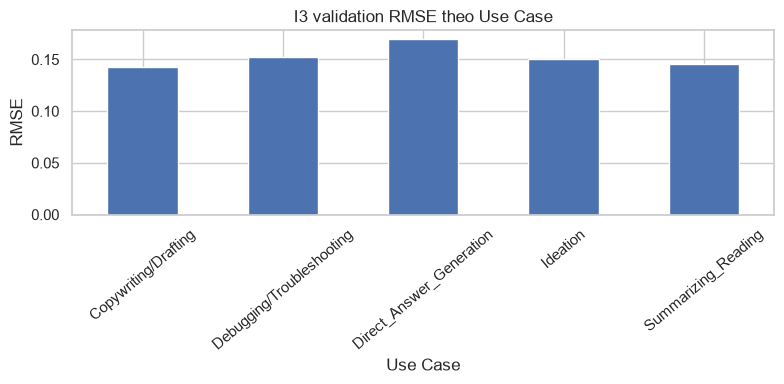

Nhận xét từ dữ liệu: Nhóm nhỏ nhất có n=942; nhóm n<30 cần thận trọng.


In [19]:
g=val[['Primary_Use_Case',TARGET]].copy(); g['pred']=valpred['I3']; subgroup=g.groupby('Primary_Use_Case').apply(lambda d: pd.Series({'n':len(d),'rmse':np.sqrt(np.mean((d[TARGET]-d.pred)**2))}),include_groups=False)
display(subgroup); fig,ax=plt.subplots(figsize=(8,4)); subgroup.rmse.plot.bar(ax=ax); ax.set(title='I3 validation RMSE theo Use Case',xlabel='Use Case',ylabel='RMSE'); ax.tick_params(axis='x',rotation=40)
show(fig,'10_subgroup_rmse',f"Nhóm nhỏ nhất có n={int(subgroup.n.min())}; nhóm n<30 cần thận trọng.")

## 27b. Sai số theo kỹ năng prompt

Báo số lượng và RMSE theo Prompt Skill; nhóm dưới 30 mẫu cần thận trọng.

,n,rmse,warning
Prompt_Engineering_Skill,,,
Advanced,2063.0,0.155686,
Beginner,2788.0,0.148116,
Intermediate,2649.0,0.149407,


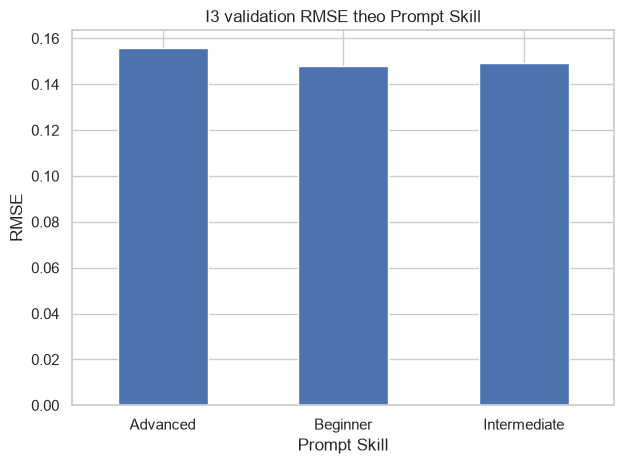

Nhận xét từ dữ liệu: Nhóm nhỏ nhất n=2063; RMSE 0.1481–0.1557.


In [20]:
gp=val[['Prompt_Engineering_Skill',TARGET]].copy(); gp['pred']=valpred['I3']; prompt_scores=gp.groupby('Prompt_Engineering_Skill').apply(lambda d: pd.Series({'n':len(d),'rmse':np.sqrt(np.mean((d[TARGET]-d.pred)**2))}),include_groups=False)
prompt_scores['warning']=prompt_scores['n'].map(lambda n:'n<30' if n<30 else '')
display(prompt_scores); prompt_scores.to_csv(TABLES/'prompt_subgroups.csv')
fig,ax=plt.subplots(); prompt_scores.rmse.plot.bar(ax=ax); ax.set(title='I3 validation RMSE theo Prompt Skill',xlabel='Prompt Skill',ylabel='RMSE'); ax.tick_params(axis='x',rotation=0)
show(fig,'10b_prompt_rmse',f"Nhóm nhỏ nhất n={int(prompt_scores.n.min())}; RMSE {prompt_scores.rmse.min():.4f}–{prompt_scores.rmse.max():.4f}.")

## 28. Đa cộng tuyến

Condition number của ma trận đã biến đổi là chỉ báo nhạy với thang đo; ma trận suy biến cần được thảo luận.

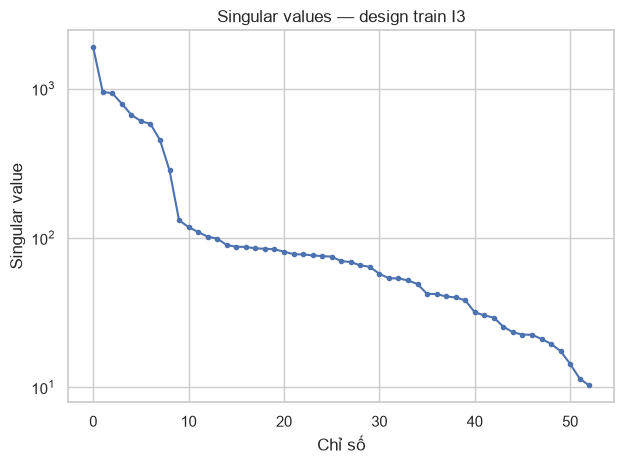

Nhận xét từ dữ liệu: Condition number (không intercept) = 184; không mặc nhiên kết luận ý nghĩa thống kê.


In [21]:
X3=f3.transform(train[INPUTS]); singular=np.linalg.svd(X3,compute_uv=False); cond=singular[0]/singular[-1] if singular[-1]>0 else np.inf
fig,ax=plt.subplots(); ax.semilogy(singular,marker='.'); ax.set(title='Singular values — design train I3',xlabel='Chỉ số',ylabel='Singular value')
show(fig,'11_singular_values',f"Condition number (không intercept) = {cond:.3g}; không mặc nhiên kết luận ý nghĩa thống kê.")

## 28b. VIF trên train

VIF dùng ma trận train chuẩn hóa, có intercept ngầm; thiết kế thiếu hạng được báo vô hạn.

,feature,vif
0,Hc,8.704548
17,Prompt_Engineering_Skill=Beginner,7.081177
18,Prompt_Engineering_Skill=Intermediate,6.596959
15,Primary_Use_Case=Ideation,5.920023
13,Primary_Use_Case=Debugging/Troubleshooting,5.816493
16,Primary_Use_Case=Summarizing_Reading,5.514228
14,Primary_Use_Case=Direct_Answer_Generation,5.010093
49,Primary_Use_Case=Ideation * Prompt_Engineering...,4.274916
46,Primary_Use_Case=Debugging/Troubleshooting * P...,4.218641
50,Primary_Use_Case=Ideation * Prompt_Engineering...,4.097355


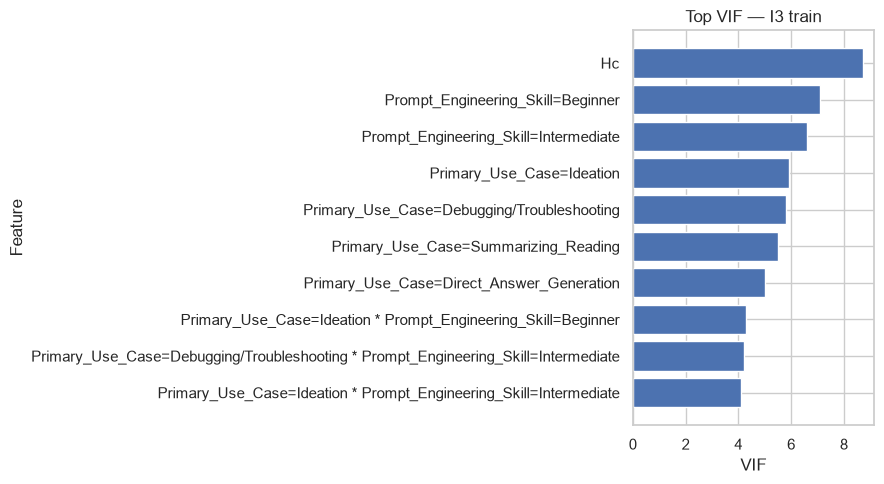

Nhận xét từ dữ liệu: VIF lớn nhất = 8.70; hạng 53/53.


In [22]:
scale=X3.std(axis=0); active=scale>1e-12; Z=(X3[:,active]-X3[:,active].mean(axis=0))/scale[active]
_,sv,vh=np.linalg.svd(Z,full_matrices=False); tol=np.finfo(float).eps*max(Z.shape)*sv[0]; rank=int((sv>tol).sum())
if rank < Z.shape[1]:
 vif=np.full(Z.shape[1],np.inf); print('Ma trận không đủ hạng: VIF được đánh dấu vô hạn.')
else: vif=len(Z)*(vh.T**2 / sv**2).sum(axis=1)
vif_table=pd.DataFrame({'feature':f3.get_feature_names_out()[active], 'vif':vif}).sort_values('vif',ascending=False); display(vif_table.head(10)); vif_table.to_csv(TABLES/'vif.csv',index=False)
finite=vif_table[np.isfinite(vif_table.vif)].head(10)
if len(finite):
 fig,ax=plt.subplots(figsize=(9,5)); ax.barh(finite.feature[::-1],finite.vif[::-1]); ax.set(title='Top VIF — I3 train',xlabel='VIF',ylabel='Feature'); show(fig,'11b_vif',f"VIF lớn nhất = {finite.vif.max():.2f}; hạng {rank}/{Z.shape[1]}.")
else: print('VIF plot: not executed — ma trận thiếu hạng.')

## 29. Khóa model và final test

Theo gate nhóm, final test chỉ chạy sau xác nhận split chung. Nếu chưa có xác nhận, ô này báo `not executed`; không đọc target test.

In [23]:
prior_metrics=OUT/'metrics.json'
if prior_metrics.exists() and json.loads(prior_metrics.read_text(encoding='utf8')).get('final_test',{}).get('status') == 'executed':
    raise RuntimeError('Final test đã được đánh giá trong output này; không chạy lại hoặc ghi đè để chọn lại model.')
lock={'selected':selected,'selection':'CV RMSE, 0.1% tie then fewer terms','fit_scope':'train','split':provenance['assignment_sha256']}
(OUT/'model_lock.json').write_text(json.dumps(lock,indent=2),encoding='utf8')
joblib.dump(models[selected], MODELS/'selected.joblib')
all_metrics={'selected':selected,'cv_rmse_mean':float(comparison.set_index('model').loc[selected,'cv_rmse_mean']),'validation':metrics(val[TARGET],valpred[selected]),'final_test':{'status':'not executed','reason':'group split approval missing'}}
if os.environ.get('LAB_GROUP_SPLIT_APPROVED') == 'yes':
    test=pd.read_csv(ROOT/'data/splits/test.csv'); yp=models[selected].predict(test.drop(columns=[TARGET])); final=metrics(test[TARGET],yp)
    final.update({'below_0_pct':float(100*np.mean(yp<0)),'above_4_pct':float(100*np.mean(yp>4))})
    all_metrics['final_test']={'status':'executed',**final}; print('Final test:', final)
else:
    test=None; print('Final test: not executed — split chung chưa được xác nhận.')
(OUT/'metrics.json').write_text(json.dumps(all_metrics,indent=2),encoding='utf8')

Final test: not executed — split chung chưa được xác nhận.


309

## 30. Kiểm tra residual cuối

Chỉ tạo hình test sau khi model lock và xác nhận split. Không dùng hình này để chọn lại model.

In [24]:
if test is not None:
    residual=test[TARGET]-yp
    fig,axs=plt.subplots(1,3,figsize=(14,4)); axs[0].scatter(test[TARGET],yp,s=4,alpha=.15); axs[0].set(title='Actual vs predicted — test',xlabel='Actual GPA',ylabel='Predicted GPA'); axs[1].scatter(yp,residual,s=4,alpha=.15); axs[1].set(title='Residual vs fitted — test',xlabel='Predicted GPA',ylabel='Residual'); axs[2].hist(residual,bins=35); axs[2].set(title='Residual distribution — test',xlabel='Residual',ylabel='Count')
    show(fig,'12_final_diagnostics',f"Residual trung bình = {residual.mean():.4f}; không dùng test để sửa model.")
else: print('Final diagnostics: not executed.')

Final diagnostics: not executed.


## 31. Dự đoán một sinh viên

Sử dụng profile thực từ train làm ví dụ hợp lệ; không nhập các interaction thủ công. Không tải joblib từ nguồn không tin cậy.

In [25]:
example=train.iloc[0][INPUTS].to_dict(); result=predict_student(example,models[selected]); print(result)

{'prediction': 2.698923576841934, 'model': 'I3', 'scenario': 'full', 'warnings': []}


## 32. What-if

Thay đổi giờ AI trong khi giữ profile khác cố định. Đây là thay đổi đầu vào của mô hình, không phải thí nghiệm can thiệp.

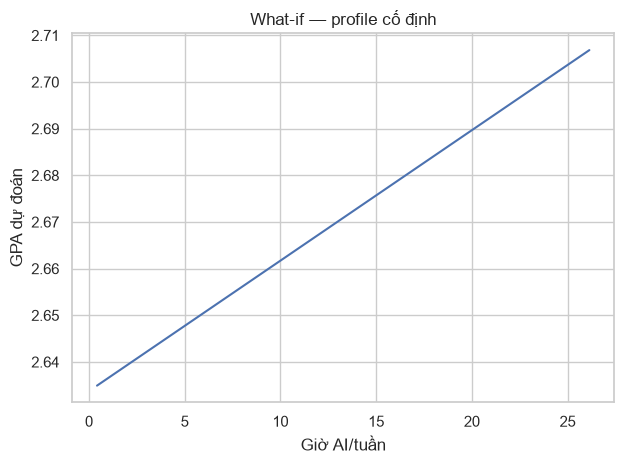

Nhận xét từ dữ liệu: Dự đoán từ 2.635 đến 2.707 trong lưới minh họa.


In [26]:
fig,ax=plt.subplots(); predictions=[predict_student(example|{H:float(h)},models[selected])['prediction'] for h in grid]; ax.plot(grid,predictions); ax.set(title='What-if — profile cố định',xlabel='Giờ AI/tuần',ylabel='GPA dự đoán')
show(fig,'12_what_if',f"Dự đoán từ {min(predictions):.3f} đến {max(predictions):.3f} trong lưới minh họa.")

## 33. Widget và fallback

Nếu frontend có ipywidgets, chọn số giờ; nếu không, dùng trực tiếp `predict_student(example, models[selected])`.

In [27]:
try:
 import ipywidgets as widgets
 from IPython.display import display
 slider=widgets.FloatSlider(description='AI giờ',min=0,max=40,value=float(example[H])); out=widgets.Output()
 def update(change=None):
  with out:
   out.clear_output(wait=True); print(predict_student(example|{H:slider.value},models[selected]))
 slider.observe(update,names='value'); display(slider,out); update()
except ImportError:
 print('ipywidgets không có; fallback:', predict_student(example,models[selected]))

ipywidgets không có; fallback: {'prediction': 2.698923576841934, 'model': 'I3', 'scenario': 'full', 'warnings': []}


## 34. Giới hạn và nguồn

Dataset synthetic không đại diện tự động cho sinh viên thực; availability nhiều biến chưa rõ. Không kết luận ý nghĩa thống kê hay nhân quả từ các hình và coefficients. Nguồn: [AI Impact on Students](https://www.kaggle.com/datasets/laveshjadon/ai-impact-on-students), tài liệu Lab 01 và `reports/DATA_DICTIONARY.md`. Chạy lại từ kernel sạch cùng split và environment đã ghi.